# 02_04 Beta

**Learning objectives**
- Use the **Beta** distribution to describe uncertainty about a **probability or proportion** (a number between 0 and 1).
- Read the parameters $\alpha$ and $\beta$ as "pseudo-counts" of successes and failures, and understand the shapes it can take.
- Derive the normalization, mean, variance and mode, and the **conjugate update**: Beta prior + Binomial data = Beta posterior.
- Solve three problems (conversion-rate uncertainty, batting-average shrinkage, order statistics) by hand, in code and by simulation.

**Prerequisites:** [01_01 Bernoulli and Binomial](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb), [02_03 Exponential, Gamma and Erlang](02_03_exponential_gamma_erlang.ipynb) (the Gamma function).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A **proportion** or **probability** is a number $p\in[0,1]$: a conversion rate, a defect rate, the bias of a coin.
- **Binomial($n,p$):** the number of successes in $n$ trials; the data's likelihood as a function of $p$ is $\binom nk p^k(1-p)^{n-k}$.
- **Gamma function:** $\Gamma(n)=(n-1)!$, and $\Gamma(\tfrac12)=\sqrt\pi$. The **Beta function** is $B(a,b)=\dfrac{\Gamma(a)\Gamma(b)}{\Gamma(a+b)}=\int_0^1t^{a-1}(1-t)^{b-1}dt$.
- **Bayes' rule (idea):** *posterior $\propto$ prior $\times$ likelihood*. First belief, times how well each value of $p$ explains the data, then renormalize.
- **Uniform(0,1):** all proportions equally likely.

## 3. Intuition and story

### 3.1 A probability that is itself uncertain
A store converts 30 of 1,000 visitors. The observed rate is 3.0 %, but that is only an *estimate* of the true conversion rate $p$: with other 1,000 visitors we would see something slightly different. What we want is a **distribution over $p$** that says which values are plausible. The natural family is the **Beta distribution**, which lives on $[0,1]$ and is flexible enough to be flat, bell-shaped, skewed or U-shaped.

### 3.2 $\alpha$ and $\beta$ as pseudo-counts
Think of **Beta($\alpha,\beta$)** as the belief you would hold after seeing $\alpha-1$ successes and $\beta-1$ failures starting from complete ignorance (Uniform = Beta(1,1)). More data (bigger $\alpha+\beta$) means a narrower, more confident curve. The mean is $\alpha/(\alpha+\beta)$, the proportion of "pseudo-successes".

### 3.3 Updating beliefs with data
Start with Beta(1,1) (flat). Observe data one batch at a time and watch the curve narrow around the truth. The picture below uses a true $p=0.3$ and shows the belief after 0, 5, 20, 100 and 500 trials. This is **Bayesian updating**; the formulas are in section 5.6.

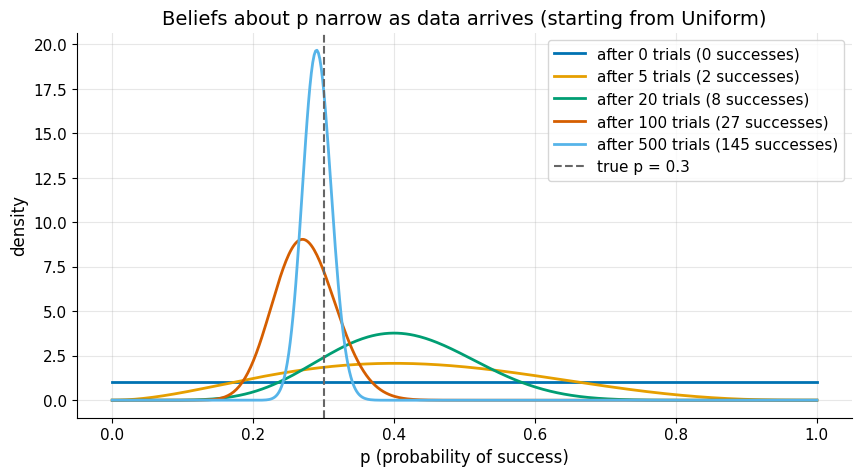

In [2]:
true_p = 0.3
all_trials = rng.binomial(1, true_p, size=500)               # 500 Bernoulli outcomes (1 = success)
p_axis = np.linspace(0, 1, 500)

fig, ax = plt.subplots(figsize=(10, 5))
for n_seen, color in zip([0, 5, 20, 100, 500], COLORS + ["black"]):
    successes = all_trials[:n_seen].sum()
    posterior = stats.beta(a=1 + successes, b=1 + n_seen - successes)     # Beta(1 + successes, 1 + failures)
    ax.plot(p_axis, posterior.pdf(p_axis), color=color, linewidth=2, label=f"after {n_seen} trials ({successes} successes)")
ax.axvline(true_p, color=NEUTRAL, linestyle="--", label="true p = 0.3")
ax.set_title("Beliefs about p narrow as data arrives (starting from Uniform)")
ax.set_xlabel("p (probability of success)")
ax.set_ylabel("density")
ax.legend()
plt.show()

**In plain words.** The Beta describes *what we believe about an unknown probability*. With no data it is flat; with a few observations it is wide; with many observations it becomes a sharp spike around the observed rate. This is the cleanest example of learning from data.

## 4. Formal definition

**Beta($\alpha,\beta$):** support $x\in[0,1]$, shape parameters $\alpha>0$ and $\beta>0$.
$$f(x)=\frac{x^{\alpha-1}(1-x)^{\beta-1}}{B(\alpha,\beta)},\qquad B(\alpha,\beta)=\frac{\Gamma(\alpha)\Gamma(\beta)}{\Gamma(\alpha+\beta)}.$$
The CDF is the **regularized incomplete beta function** $I_x(\alpha,\beta)$ (no elementary form; `scipy` computes it).

Shapes: $\alpha=\beta=1$ is Uniform; $\alpha=\beta>1$ symmetric bell; $\alpha<\beta$ skewed toward 0; $\alpha>\beta$ skewed toward 1; $\alpha,\beta<1$ **U-shaped** (mass piled at 0 and 1).

**`scipy`:** `stats.beta(a=alpha, b=beta)`; for another interval use `loc` and `scale`.

## 5. Derivations

### 5.1 Normalization
By definition $B(\alpha,\beta)=\int_0^1t^{\alpha-1}(1-t)^{\beta-1}dt$, so the density integrates to 1. The identity $B(\alpha,\beta)=\Gamma(\alpha)\Gamma(\beta)/\Gamma(\alpha+\beta)$ follows by writing $\Gamma(\alpha)\Gamma(\beta)$ as a double integral and changing variables to $s=x+y$, $t=x/(x+y)$.

### 5.2 Mean
$$E[X]=\int_0^1x\frac{x^{\alpha-1}(1-x)^{\beta-1}}{B(\alpha,\beta)}dx=\frac{B(\alpha+1,\beta)}{B(\alpha,\beta)}=\frac{\Gamma(\alpha+1)\Gamma(\alpha+\beta)}{\Gamma(\alpha)\Gamma(\alpha+\beta+1)}=\frac{\alpha}{\alpha+\beta}.$$

### 5.3 Variance
The same trick gives $E[X^2]=\dfrac{B(\alpha+2,\beta)}{B(\alpha,\beta)}=\dfrac{\alpha(\alpha+1)}{(\alpha+\beta)(\alpha+\beta+1)}$, so
$$\mathrm{Var}(X)=\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}.$$
For a fixed mean, the variance falls as $\alpha+\beta$ (the amount of data) grows: $\mathrm{Var}=\dfrac{\mu(1-\mu)}{\alpha+\beta+1}$ with $\mu=\alpha/(\alpha+\beta)$.

### 5.4 Mode
For $\alpha,\beta>1$, maximize $\ln f=(\alpha-1)\ln x+(\beta-1)\ln(1-x)$: derivative $\frac{\alpha-1}x-\frac{\beta-1}{1-x}=0$ gives $\text{mode}=\dfrac{\alpha-1}{\alpha+\beta-2}$.

### 5.5 Skewness
$\text{skewness}=\dfrac{2(\beta-\alpha)\sqrt{\alpha+\beta+1}}{(\alpha+\beta+2)\sqrt{\alpha\beta}}$ (stated): positive when $\beta>\alpha$. The MGF involves a confluent hypergeometric function and is not used.

### 5.6 Conjugacy: Beta prior times Binomial likelihood
Prior $p\sim\text{Beta}(\alpha,\beta)$: $\pi(p)\propto p^{\alpha-1}(1-p)^{\beta-1}$. Data: $k$ successes in $n$ trials, likelihood $\propto p^k(1-p)^{n-k}$. Multiply:
$$\text{posterior}(p)\propto p^{\alpha+k-1}(1-p)^{\beta+n-k-1}.$$
This is the kernel of **Beta($\alpha+k,\ \beta+n-k$)**. The prior and posterior are in the *same family*: the Beta is **conjugate** to the Binomial. Updating is just addition: add the successes to $\alpha$ and the failures to $\beta$.

**Posterior mean as a weighted average.**
$$E[p\mid\text{data}]=\frac{\alpha+k}{\alpha+\beta+n}=\underbrace{\frac{\alpha+\beta}{\alpha+\beta+n}}_{\text{weight on prior}}\cdot\frac\alpha{\alpha+\beta}+\underbrace{\frac n{\alpha+\beta+n}}_{\text{weight on data}}\cdot\frac kn.$$
With little data the prior dominates; with lots of data the observed rate $k/n$ takes over. This is called **shrinkage** (extreme observed rates are pulled toward the prior mean).

**In plain words.** Beta($\alpha,\beta$) is the same as having already seen $\alpha$ successes and $\beta$ failures. New data just adds to those counts.

### 5.7 Beta from Gammas
If $X\sim\text{Gamma}(\alpha,1)$ and $Y\sim\text{Gamma}(\beta,1)$ are independent then $\dfrac X{X+Y}\sim\text{Beta}(\alpha,\beta)$. This is how Beta samples are generated and why the Beta relates to the Dirichlet (Module 03).

### 5.8 Order statistics of uniforms
Draw $n$ independent Uniform(0,1) values and sort them. The $k$-th smallest has the Beta($k,\ n-k+1$) distribution. The *median of 5 uniform values* is the 3rd smallest: Beta(3,3). (Reason: $P(U_{(k)}\le x)=P(\text{at least }k\text{ of the }n\text{ values}\le x)$, a Binomial tail, which equals the Beta CDF.)

## 6. Properties and relationships

- **Uniform(0,1) = Beta(1,1).**
- **Conjugate prior** for Bernoulli, Binomial and Geometric likelihoods; Negative Binomial too.
- **Symmetry:** if $X\sim\text{Beta}(\alpha,\beta)$ then $1-X\sim\text{Beta}(\beta,\alpha)$.
- **Ratio of Gammas:** $X/(X+Y)$ above; also $\frac{X}{Y}$ is a "Beta prime" (the F distribution is related).
- **Binomial link:** $P(\text{Bin}(n,p)\le k)=1-I_p(k+1,n-k)=P(\text{Beta}(k+1,n-k)>p)$.
- **Normal limit:** for large $\alpha+\beta$ the Beta is nearly Normal with the mean and variance above.
- **Generalizes:** the multivariate version is the Dirichlet (Module 03).

## 7. 2D visuals

### 7.1 PDF and CDF
Beta(5, 2): skewed toward 1 with mean 5/7 = 0.71. The vertical line marks the mean and the dotted line the mode (alpha-1)/(alpha+beta-2) = 0.8.

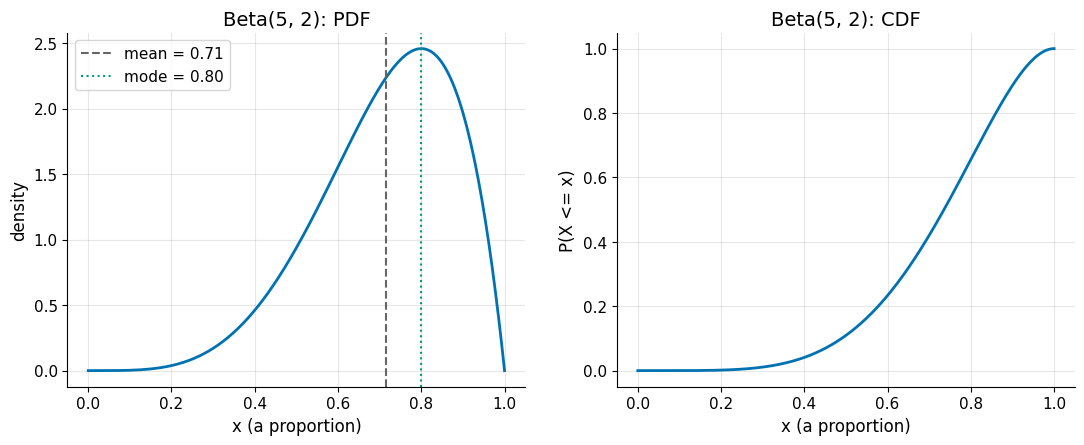

In [3]:
alpha, beta_ = 5, 2
dist = stats.beta(a=alpha, b=beta_)
x_axis = np.linspace(0, 1, 500)

fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_pdf.plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2)
ax_pdf.axvline(dist.mean(), color=NEUTRAL, linestyle="--", label=f"mean = {dist.mean():.2f}")
ax_pdf.axvline((alpha - 1) / (alpha + beta_ - 2), color=COLORS[2], linestyle=":", label="mode = 0.80")
ax_pdf.set_title("Beta(5, 2): PDF")
ax_pdf.set_xlabel("x (a proportion)")
ax_pdf.set_ylabel("density")
ax_pdf.legend()

ax_cdf.plot(x_axis, dist.cdf(x_axis), color=MAIN, linewidth=2)
ax_cdf.set_title("Beta(5, 2): CDF")
ax_cdf.set_xlabel("x (a proportion)")
ax_cdf.set_ylabel("P(X <= x)")
plt.show()

### 7.2 The zoo of shapes
The Beta can be flat, bell-shaped, J-shaped, skewed or U-shaped, depending on alpha and beta. Reading guide: alpha and beta both above 1 gives a bump; both below 1 gives a U (extreme values most likely).

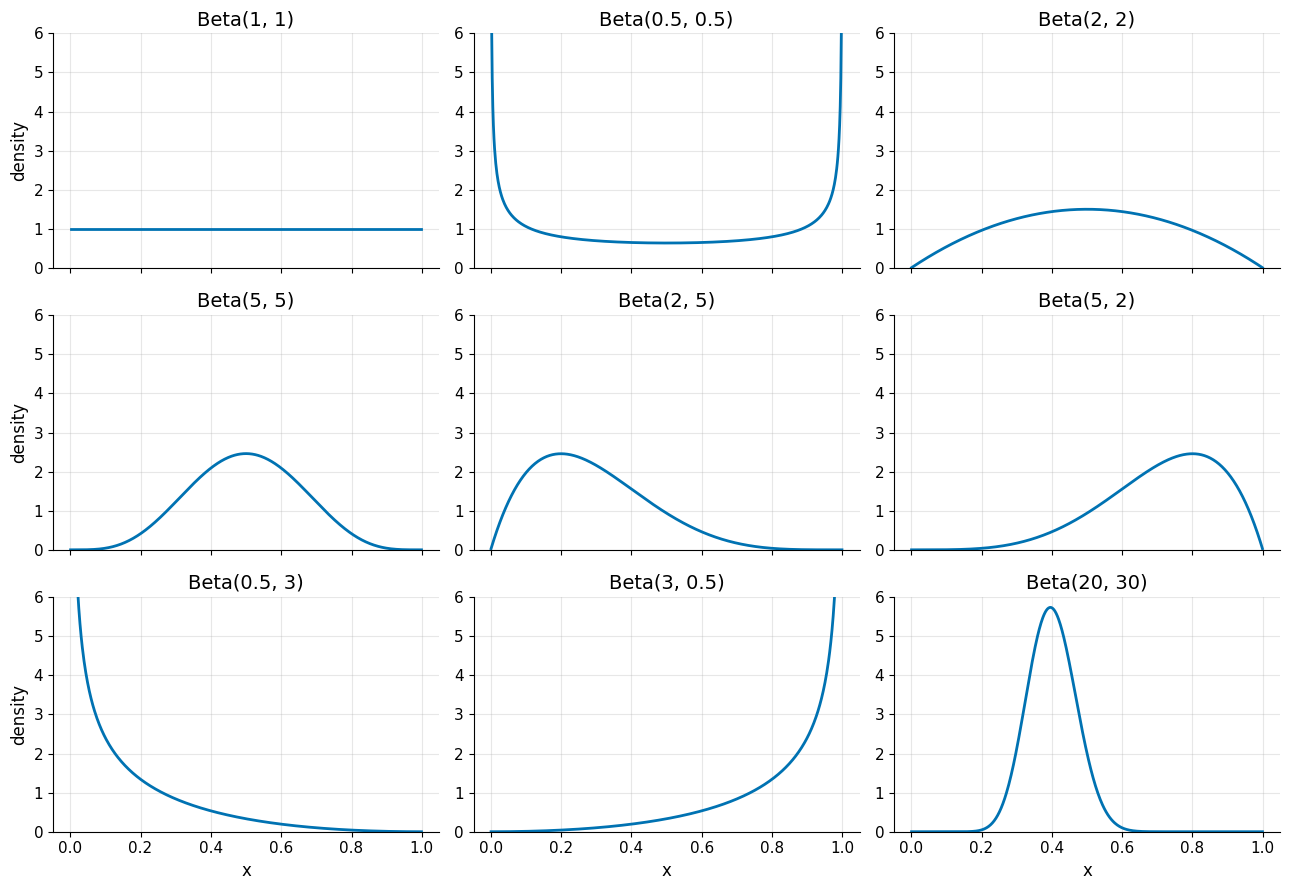

In [4]:
shapes = [(1, 1), (0.5, 0.5), (2, 2), (5, 5), (2, 5), (5, 2), (0.5, 3), (3, 0.5), (20, 30)]
x_axis = np.linspace(0.001, 0.999, 600)
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, (a, b) in zip(axes.ravel(), shapes):
    ax.plot(x_axis, stats.beta(a, b).pdf(x_axis), color=MAIN, linewidth=2)
    ax.set_title(f"Beta({a}, {b})")
    ax.set_ylim(0, 6)
for ax in axes[-1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("density")
plt.tight_layout()
plt.show()

### 7.3 Effect of alpha and beta on the mean and the spread
Left: fixing beta = 4 and raising alpha moves the mean right. Right: keeping the mean at 0.3 while scaling both parameters (alpha + beta = 5, 10, 40, 160) shrinks the spread: more pseudo-data means more confidence.

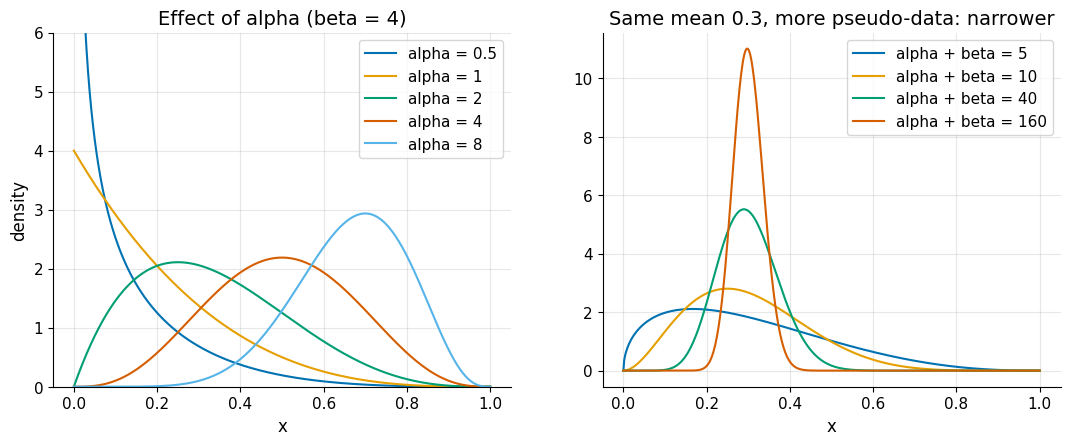

In [5]:
x_axis = np.linspace(0, 1, 500)
fig, (ax_alpha, ax_total) = plt.subplots(1, 2, figsize=(13, 4.6))
for a, color in zip([0.5, 1, 2, 4, 8], COLORS + ["black"]):
    ax_alpha.plot(x_axis, stats.beta(a, 4).pdf(x_axis), color=color, label=f"alpha = {a}")
ax_alpha.set_title("Effect of alpha (beta = 4)")
ax_alpha.set_xlabel("x")
ax_alpha.set_ylabel("density")
ax_alpha.set_ylim(0, 6)
ax_alpha.legend()

for total, color in zip([5, 10, 40, 160], COLORS):
    ax_total.plot(x_axis, stats.beta(0.3 * total, 0.7 * total).pdf(x_axis), color=color, label=f"alpha + beta = {total}")
ax_total.set_title("Same mean 0.3, more pseudo-data: narrower")
ax_total.set_xlabel("x")
ax_total.legend()
plt.show()

### 7.4 Prior, data and posterior
A prior belief Beta(2, 38) (conversion rate around 5 %) is updated by 30 successes in 1,000 trials: Beta(32, 1008). The posterior sits almost on top of the observed rate 3 %, because 1,000 trials outweigh the 40 pseudo-trials of the prior.

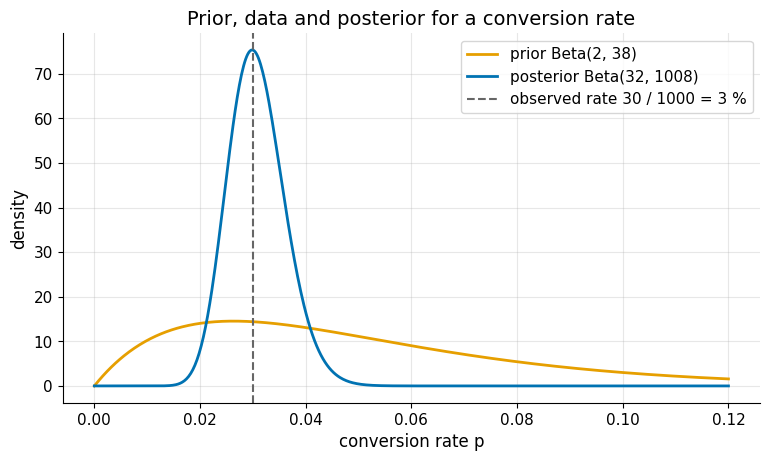

In [6]:
prior = stats.beta(2, 38)
posterior = stats.beta(2 + 30, 38 + 970)
p_axis = np.linspace(0, 0.12, 600)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(p_axis, prior.pdf(p_axis), color=COLORS[1], linewidth=2, label="prior Beta(2, 38)")
ax.plot(p_axis, posterior.pdf(p_axis), color=MAIN, linewidth=2, label="posterior Beta(32, 1008)")
ax.axvline(0.03, color=NEUTRAL, linestyle="--", label="observed rate 30 / 1000 = 3 %")
ax.set_title("Prior, data and posterior for a conversion rate")
ax.set_xlabel("conversion rate p")
ax.set_ylabel("density")
ax.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: PDF over (x, alpha), beta = 3
For each alpha a curve: alpha below 1 piles mass at 0; larger alpha moves the ridge toward 1.

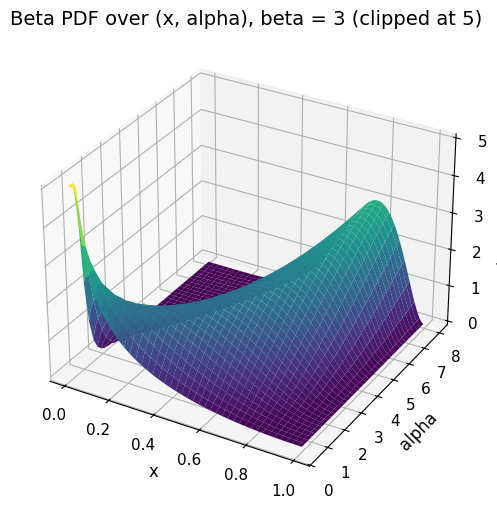

In [7]:
x_values = np.linspace(0.005, 0.995, 120)
alpha_values = np.linspace(0.5, 8, 40)
X, A = np.meshgrid(x_values, alpha_values)
Z = stats.beta.pdf(X, A, 3)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, A, np.minimum(Z, 5), cmap="viridis", edgecolor="none")
ax.set_title("Beta PDF over (x, alpha), beta = 3 (clipped at 5)")
ax.set_xlabel("x")
ax.set_ylabel("alpha")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: the posterior as data accumulates
A surface over (p, number of trials n) for data with a constant 30 % success rate and a Uniform prior: the ridge sharpens as n grows. This is the picture of learning.

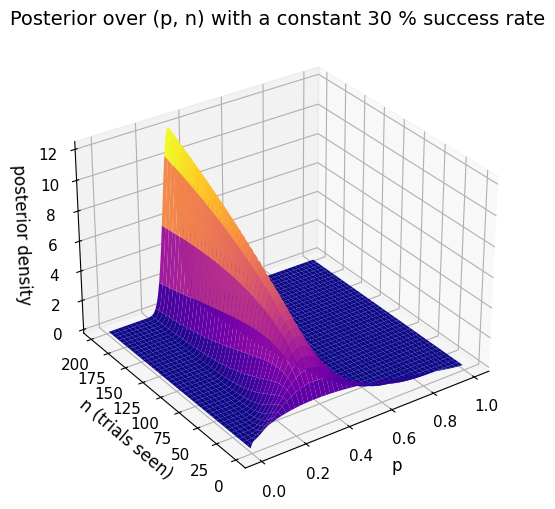

In [8]:
p_values = np.linspace(0, 1, 150)
n_values = np.arange(2, 202, 5)
P, N = np.meshgrid(p_values, n_values)
Z_post = stats.beta.pdf(P, 1 + 0.3 * N, 1 + 0.7 * N)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(P, N, Z_post, cmap="plasma", edgecolor="none")
ax.set_title("Posterior over (p, n) with a constant 30 % success rate")
ax.set_xlabel("p")
ax.set_ylabel("n (trials seen)")
ax.set_zlabel("posterior density")
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.3 Interactive Plotly version
The learning surface of 8.2; rotate and hover.

In [9]:
fig = go.Figure(go.Surface(x=p_values, y=n_values, z=Z_post, colorscale="Plasma"))
fig.update_layout(title="Posterior over (p, n) with a constant 30 % success rate", width=750, height=550,
                  scene=dict(xaxis_title="p", yaxis_title="n (trials seen)", zaxis_title="posterior density"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PDF
50,000 draws from Beta(5, 2).

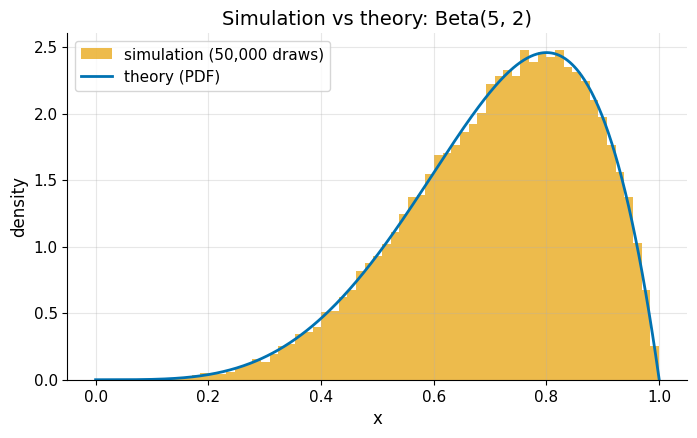

sample mean 0.7150 (theory 0.7143), sample variance 0.02551 (theory 0.02551)


In [10]:
samples = rng.beta(a=5, b=2, size=50_000)
x_axis = np.linspace(0, 1, 500)
fig, ax = plt.subplots()
ax.hist(samples, bins=60, density=True, color=SIM, alpha=0.7, label="simulation (50,000 draws)")
ax.plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2, label="theory (PDF)")
ax.set_title("Simulation vs theory: Beta(5, 2)")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()
print(f"sample mean {samples.mean():.4f} (theory {5 / 7:.4f}), sample variance {samples.var():.5f} (theory {dist.var():.5f})")

### 9.2 Running mean converges to alpha/(alpha+beta)

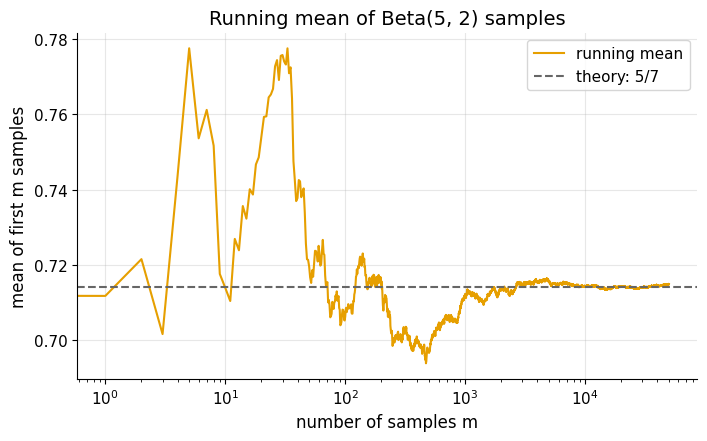

In [11]:
running_mean = np.cumsum(samples) / np.arange(1, len(samples) + 1)
fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(5 / 7, color=NEUTRAL, linestyle="--", label="theory: 5/7")
ax.set_xscale("log")
ax.set_title("Running mean of Beta(5, 2) samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.legend()
plt.show()

### 9.3 Beta from two Gammas
Take X from Gamma(5) and Y from Gamma(2); the ratio X / (X + Y) has a Beta(5, 2) distribution.

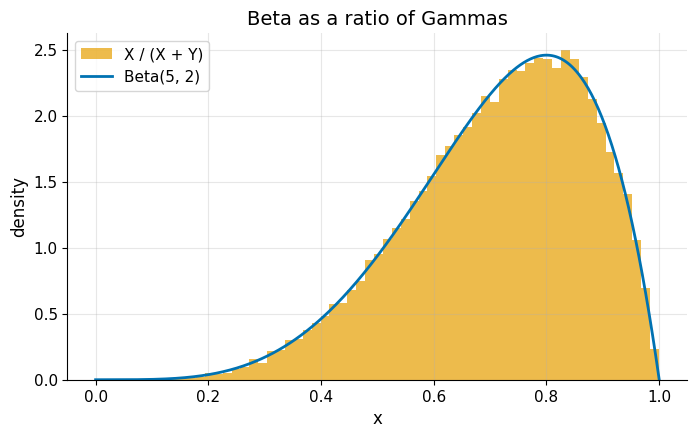

KS test p-value against Beta(5, 2): 0.668 (large means consistent)


In [12]:
gamma_x = rng.gamma(shape=5, scale=1, size=50_000)
gamma_y = rng.gamma(shape=2, scale=1, size=50_000)
ratio = gamma_x / (gamma_x + gamma_y)

fig, ax = plt.subplots()
ax.hist(ratio, bins=60, density=True, color=SIM, alpha=0.7, label="X / (X + Y)")
ax.plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2, label="Beta(5, 2)")
ax.set_title("Beta as a ratio of Gammas")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()
print(f"KS test p-value against Beta(5, 2): {stats.kstest(ratio, dist.cdf).pvalue:.3f} (large means consistent)")

## 10. `scipy.stats` cheat sheet

In [13]:
b = stats.beta(a=31, b=971)                 # posterior for 30 successes in 1000 trials with a Uniform prior
print("pdf(0.03)        density at 0.03 :", round(b.pdf(0.03), 3))
print("cdf(0.03)        P(p <= 0.03)    :", round(b.cdf(0.03), 4))
print("sf(0.03)         P(p > 0.03)     :", round(b.sf(0.03), 4))
print("ppf(0.5)         median          :", round(b.ppf(0.5), 5))
print("interval(0.95)   95% credible    :", np.round(b.interval(0.95), 5))
print("mean, var        :", round(b.mean(), 5), round(b.var(), 8))
print("rvs(3)           :", b.rvs(size=3, random_state=1).round(4))
print("stats mvsk       :", np.round(b.stats(moments="mvsk"), 4))

pdf(0.03)        density at 0.03 : 73.823
cdf(0.03)        P(p <= 0.03)    : 0.4539
sf(0.03)         P(p > 0.03)     : 0.5461
ppf(0.5)         median          : 0.03063
interval(0.95)   95% credible    : [0.02114 0.04251]
mean, var        : 0.03094 2.989e-05
rvs(3)           : [0.0409 0.0288 0.0419]
stats mvsk       : [0.0309 0.     0.3418 0.1691]


**Fitting:** fix the support to [0, 1] with `floc=0, fscale=1`; then only alpha and beta are estimated.

In [14]:
proportions = rng.beta(3, 7, size=2000)
a_hat, b_hat, loc_hat, scale_hat = stats.beta.fit(proportions, floc=0, fscale=1)
print(f"true (3, 7) -> fitted alpha = {a_hat:.2f}, beta = {b_hat:.2f}")

true (3, 7) -> fitted alpha = 2.99, beta = 6.76


## 11. Real-world worked examples

---
### Example 1 (main): uncertainty about a conversion rate

**Scenario (illustrative numbers).** A landing page was shown to **1,000 visitors** and **30 converted** (3.0 %). The marketing team asks whether the page beats its target of **3 %**. We treat the true conversion rate $p$ as unknown and update a Beta prior. Two priors:
- **Flat prior** Beta(1,1): no opinion.
- **Informed prior** Beta(2, 38): past pages converted around 5 % (mean $2/40$), worth about 40 pseudo-visitors.

**Questions**
1. What is the **posterior distribution** and its mean under each prior?
2. What is the **95 % credible interval** for $p$?
3. What is the probability that $p$ is **above the 3 % target**?

### 11.1 By hand
**Posterior.** Add the data to the prior counts (section 5.6): $k=30$ successes, $n-k=970$ failures.
- Flat: Beta($1+30,\ 1+970$) = Beta(31, 971).
- Informed: Beta($2+30,\ 38+970$) = Beta(32, 1008).

**Q1.** Means: $\dfrac{31}{31+971}=\dfrac{31}{1002}=0.03094$ and $\dfrac{32}{1040}=0.03077$. Both are very close to the observed 3.0 %.

**Q2.** For Beta(31, 971): variance $=\dfrac{31\times971}{1002^2\times1003}=2.99\times10^{-5}$, SD $=0.00547$. A normal approximation gives $0.03094\pm1.96\times0.00547=(0.0202,\ 0.0417)$. The exact interval comes from the Beta quantiles in code.

**Q3.** Normal approximation: $z=\dfrac{0.03-0.03094}{0.00547}=-0.17$, so $P(p>0.03)\approx\Phi(0.17)=0.568$. The exact tail uses the incomplete beta function (code).

Below, the **exact** tail probability is computed by plain numerical integration of the Beta density (no `scipy`), then compared.

In [15]:
import math

def beta_pdf_by_formula(x, a, b):
    # x^(a-1) (1-x)^(b-1) / B(a, b), with B written through the Gamma function (log scale for stability)
    log_beta_function = math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b)
    return math.exp((a - 1) * math.log(x) + (b - 1) * math.log(1 - x) - log_beta_function)

def beta_tail_by_integration(threshold, a, b, steps=200_000):
    # P(p > threshold) = integral of the density from threshold to 1 (trapezoid rule, plain loop)
    width = (1 - threshold) / steps
    total = 0.0
    previous = beta_pdf_by_formula(threshold, a, b)
    for i in range(1, steps):
        current = beta_pdf_by_formula(threshold + i * width, a, b)
        total += 0.5 * (previous + current) * width
        previous = current
    return total

a_flat, b_flat = 1 + 30, 1 + 970
a_info, b_info = 2 + 30, 38 + 970
mean_flat_hand = a_flat / (a_flat + b_flat)
mean_info_hand = a_info / (a_info + b_info)
sd_flat_hand = math.sqrt(a_flat * b_flat / ((a_flat + b_flat) ** 2 * (a_flat + b_flat + 1)))
p_above_flat_hand = beta_tail_by_integration(0.03, a_flat, b_flat)
p_above_info_hand = beta_tail_by_integration(0.03, a_info, b_info)
print(f"means: {mean_flat_hand:.5f} (flat), {mean_info_hand:.5f} (informed); SD flat = {sd_flat_hand:.5f}")
print(f"P(p > 3%): flat {p_above_flat_hand:.4f}, informed {p_above_info_hand:.4f}")

means: 0.03094 (flat), 0.03077 (informed); SD flat = 0.00547
P(p > 3%): flat 0.5461, informed 0.5352


### 11.2 In code with `scipy`, and the asserts

In [16]:
posterior_flat = stats.beta(a_flat, b_flat)
posterior_info = stats.beta(a_info, b_info)

assert np.isclose(mean_flat_hand, posterior_flat.mean())
assert np.isclose(mean_info_hand, posterior_info.mean())
assert np.isclose(sd_flat_hand, posterior_flat.std())
assert np.isclose(p_above_flat_hand, posterior_flat.sf(0.03), atol=1e-4)
assert np.isclose(p_above_info_hand, posterior_info.sf(0.03), atol=1e-4)

for name, post in [("flat prior Beta(1,1)", posterior_flat), ("informed prior Beta(2,38)", posterior_info)]:
    low, high = post.interval(0.95)
    print(f"{name:26s} mean {post.mean():.4f}, 95% credible interval ({low:.4f}, {high:.4f}), P(p > 3%) = {post.sf(0.03):.3f}")

flat prior Beta(1,1)       mean 0.0309, 95% credible interval (0.0211, 0.0425), P(p > 3%) = 0.546
informed prior Beta(2,38)  mean 0.0308, 95% credible interval (0.0212, 0.0421), P(p > 3%) = 0.535


### 11.3 Verify by simulation
Draw 500,000 values of p from each posterior; the proportion above 3 % and the interval from the percentiles should match.

In [17]:
sim_flat = rng.beta(a_flat, b_flat, size=500_000)
sim_info = rng.beta(a_info, b_info, size=500_000)
print(f"flat:     P(p > 3%) exact {posterior_flat.sf(0.03):.4f} simulated {np.mean(sim_flat > 0.03):.4f}; interval {np.percentile(sim_flat, [2.5, 97.5]).round(4)}")
print(f"informed: P(p > 3%) exact {posterior_info.sf(0.03):.4f} simulated {np.mean(sim_info > 0.03):.4f}; interval {np.percentile(sim_info, [2.5, 97.5]).round(4)}")
assert abs(np.mean(sim_flat > 0.03) - posterior_flat.sf(0.03)) < 0.003

# frequentist check: draw new groups of 1000 visitors with p drawn from the posterior (posterior predictive)
future = rng.binomial(1000, sim_flat[:100_000])
print(f"a future batch of 1000 visitors would convert between {np.percentile(future, 2.5):.0f} and {np.percentile(future, 97.5):.0f} (95 % predictive range)")

flat:     P(p > 3%) exact 0.5461 simulated 0.5462; interval [0.0211 0.0425]
informed: P(p > 3%) exact 0.5352 simulated 0.5365; interval [0.0212 0.0421]
a future batch of 1000 visitors would convert between 17 and 47 (95 % predictive range)


### 11.4 Plots with the regions shaded

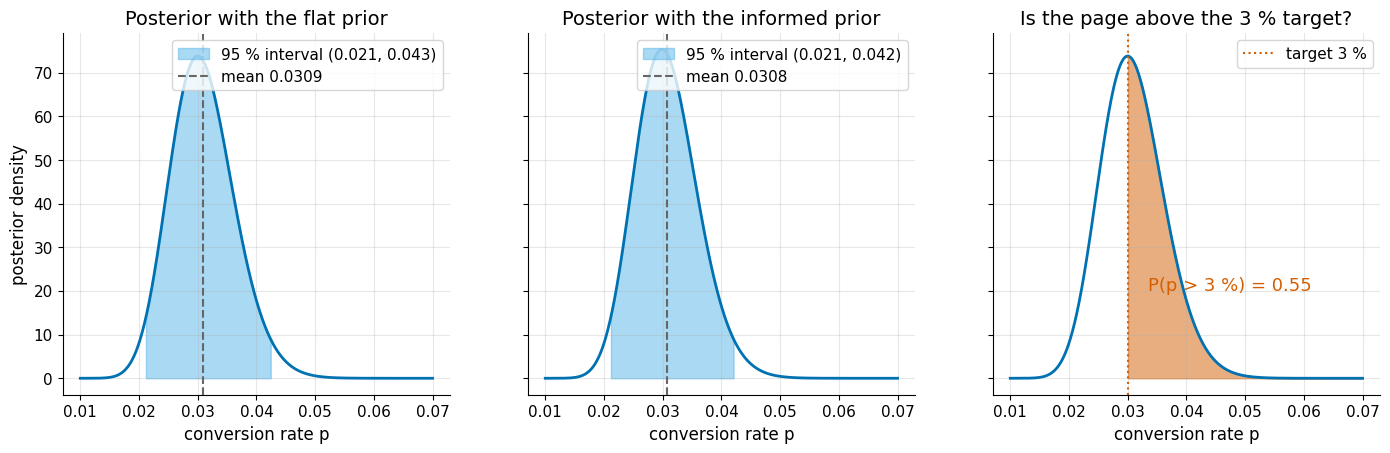

In [18]:
p_axis = np.linspace(0.01, 0.07, 800)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7), sharey=True)

for ax, post, name in [(axes[0], posterior_flat, "flat prior"), (axes[1], posterior_info, "informed prior")]:
    low, high = post.interval(0.95)
    ax.plot(p_axis, post.pdf(p_axis), color=MAIN, linewidth=2)
    inside = (p_axis >= low) & (p_axis <= high)
    ax.fill_between(p_axis[inside], post.pdf(p_axis[inside]), color=COLORS[4], alpha=0.5, label=f"95 % interval ({low:.3f}, {high:.3f})")
    ax.axvline(post.mean(), color=NEUTRAL, linestyle="--", label=f"mean {post.mean():.4f}")
    ax.set_title(f"Posterior with the {name}")
    ax.set_xlabel("conversion rate p")
    ax.legend(loc="upper right")
axes[0].set_ylabel("posterior density")

above = p_axis > 0.03
axes[2].plot(p_axis, posterior_flat.pdf(p_axis), color=MAIN, linewidth=2)
axes[2].fill_between(p_axis[above], posterior_flat.pdf(p_axis[above]), color=HIGHLIGHT, alpha=0.5)
axes[2].axvline(0.03, color=HIGHLIGHT, linestyle=":", label="target 3 %")
axes[2].text(0.0335, 20, f"P(p > 3 %) = {posterior_flat.sf(0.03):.2f}", color=HIGHLIGHT, fontsize=13)
axes[2].set_title("Is the page above the 3 % target?")
axes[2].set_xlabel("conversion rate p")
axes[2].legend(loc="upper right")
plt.show()

### 11.5 Interpretation and decision
- With either prior the best estimate of the conversion rate is **about 3.1 %**, and the plausible range (95 % credible interval) is roughly **2.1 % to 4.3 %**.
- The informed and flat priors give almost the same answer because 1,000 visitors carry far more weight than 40 pseudo-visitors. **With little data they would differ a lot**: try 3 conversions out of 100 and compare.
- The probability that the page really beats the 3 % target is only about **55 %**, barely better than a coin flip. **Decision:** the data do **not** prove the page beats the target. Keep testing: to reach strong evidence (say 95 %) the team needs many more visitors or a bigger improvement.

---
### Example 2: batting average and shrinkage

**Scenario (illustrative).** In the league, the batting average (hits per at-bat) across players is well described by Beta(81, 219): mean $81/300=0.270$, worth about 300 pseudo at-bats. A rookie has **9 hits in his first 20 at-bats** (observed 0.450).

**Questions:** (a) his posterior mean; (b) how much weight do the data get? (c) the probability that his true average is above 0.300.

**By hand.** Posterior: Beta($81+9$, $219+11$) = Beta(90, 230); mean $=90/320=0.2813$. Weight on data $=\dfrac{20}{300+20}=0.0625$, on prior $0.9375$. Check: $0.9375\times0.270+0.0625\times0.450=0.2813$.

In [19]:
prior_league = stats.beta(81, 219)
rookie = stats.beta(81 + 9, 219 + 11)

posterior_mean_hand = (81 + 9) / (300 + 20)
weight_on_data_hand = 20 / (300 + 20)
assert np.isclose(posterior_mean_hand, rookie.mean())
assert np.isclose(0.9375 * 0.270 + weight_on_data_hand * 0.450, posterior_mean_hand)
print(f"raw average 0.450; posterior mean {rookie.mean():.4f} (weight on the data {weight_on_data_hand:.3f}); P(true average > 0.300) = {rookie.sf(0.300):.3f}")
print(f"95 % credible interval for the rookie: {np.round(rookie.interval(0.95), 3)}")
simulated = rng.beta(90, 230, size=300_000)
print(f"simulation: mean {simulated.mean():.4f}, P(> 0.300) = {np.mean(simulated > 0.300):.3f}")

raw average 0.450; posterior mean 0.2812 (weight on the data 0.062); P(true average > 0.300) = 0.225
95 % credible interval for the rookie: [0.233 0.332]
simulation: mean 0.2814, P(> 0.300) = 0.228


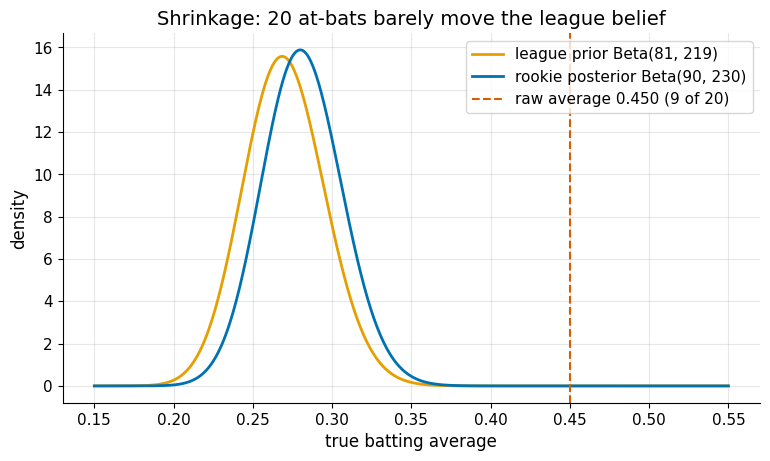

In [20]:
p_axis = np.linspace(0.15, 0.55, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(p_axis, prior_league.pdf(p_axis), color=COLORS[1], linewidth=2, label="league prior Beta(81, 219)")
ax.plot(p_axis, rookie.pdf(p_axis), color=MAIN, linewidth=2, label="rookie posterior Beta(90, 230)")
ax.axvline(0.45, color=HIGHLIGHT, linestyle="--", label="raw average 0.450 (9 of 20)")
ax.set_title("Shrinkage: 20 at-bats barely move the league belief")
ax.set_xlabel("true batting average")
ax.set_ylabel("density")
ax.legend()
plt.show()

**Interpretation.** A raw average of 0.450 after 20 at-bats is mostly luck. Bayesian shrinkage pulls the estimate down to **0.281**, only a little above the league mean, and says the chance that he is truly a 0.300 hitter is about **22 %**. Shrinkage protects against over-reacting to small samples (it is how many sports and recommendation systems rank items with few ratings).

---
### Example 3: the median of 5 uniform values (order statistics)

**Scenario.** Pick 5 numbers at random in (0, 1) and take the median (the 3rd smallest). Its distribution is Beta(3, 3) (section 5.8).

**Questions:** (a) mean and SD of the median; (b) $P(\text{median}>0.7)$; (c) compare with the Beta of the *minimum* (Beta(1,5)) and the *maximum* (Beta(5,1)).

**By hand.** (a) mean $=3/6=0.5$, variance $=\dfrac{9}{36\times7}=0.0357$, SD $=0.189$. (b) $P(\text{median}>0.7)=P(\text{at least 3 of 5 values}>0.7)=\sum_{j=3}^{5}\binom5j0.3^j0.7^{5-j}=0.1323+0.0284+0.0024=0.1631$. (c) minimum mean $=1/6=0.167$, maximum mean $=5/6=0.833$.

In [21]:
median_dist = stats.beta(3, 3)
p_median_over_07_hand = sum(math.comb(5, j) * 0.3**j * 0.7 ** (5 - j) for j in range(3, 6))
assert np.isclose(p_median_over_07_hand, median_dist.sf(0.7))
print(f"median of 5: mean {median_dist.mean():.3f}, SD {median_dist.std():.4f}, P(> 0.7) = {median_dist.sf(0.7):.4f}")

five_uniforms = np.sort(rng.uniform(size=(300_000, 5)), axis=1)
print(f"simulation: median mean {five_uniforms[:, 2].mean():.4f}, SD {five_uniforms[:, 2].std():.4f}, P(> 0.7) = {np.mean(five_uniforms[:, 2] > 0.7):.4f}")
print(f"minimum mean: simulated {five_uniforms[:, 0].mean():.4f}, Beta(1, 5) {stats.beta(1, 5).mean():.4f}; maximum mean: simulated {five_uniforms[:, 4].mean():.4f}, Beta(5, 1) {stats.beta(5, 1).mean():.4f}")
assert abs(np.mean(five_uniforms[:, 2] > 0.7) - median_dist.sf(0.7)) < 0.003

median of 5: mean 0.500, SD 0.1890, P(> 0.7) = 0.1631
simulation: median mean 0.4997, SD 0.1886, P(> 0.7) = 0.1624
minimum mean: simulated 0.1663, Beta(1, 5) 0.1667; maximum mean: simulated 0.8334, Beta(5, 1) 0.8333


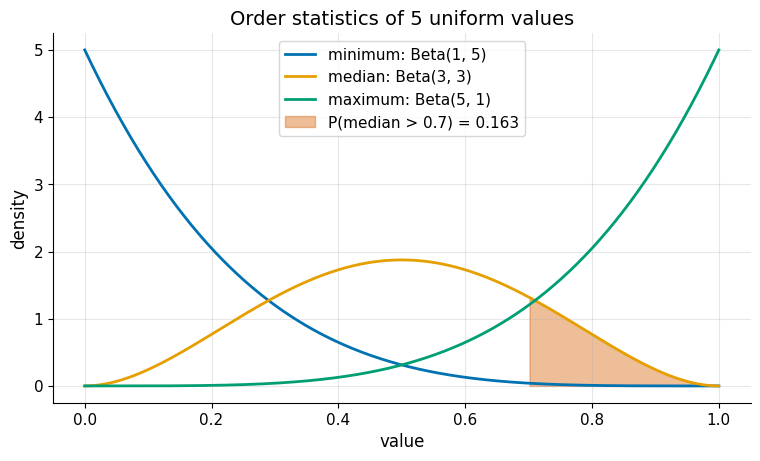

In [22]:
x_axis = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(9, 4.8))
for index, (a, b, name) in enumerate([(1, 5, "minimum: Beta(1, 5)"), (3, 3, "median: Beta(3, 3)"), (5, 1, "maximum: Beta(5, 1)")]):
    ax.plot(x_axis, stats.beta(a, b).pdf(x_axis), color=COLORS[index], linewidth=2, label=name)
over = x_axis > 0.7
ax.fill_between(x_axis[over], stats.beta(3, 3).pdf(x_axis[over]), color=HIGHLIGHT, alpha=0.4, label="P(median > 0.7) = 0.163")
ax.set_title("Order statistics of 5 uniform values")
ax.set_xlabel("value")
ax.set_ylabel("density")
ax.legend()
plt.show()

**Interpretation.** Even the median of just 5 random values is fairly spread out (SD 0.19): a sample of size 5 says little about the middle of the distribution. The minimum is typically near 0.17 and the maximum near 0.83, so a "range" from a tiny sample is a poor guide to the full range.

## 12. Where it is used

### Statistics
- **Bayesian inference for proportions:** posterior and credible intervals for a conversion rate, defect rate or prevalence (Module 07).
- **Beta-Binomial models** for overdispersed proportions, and Beta regression for rates.
- **Order statistics** and non-parametric tolerance intervals.

### Data science
- **A/B testing (Bayesian):** the probability that variant B beats A, from two Beta posteriors.
- **Ranking items with few ratings** (shrinkage toward a prior), click-through-rate estimation.
- **Thompson sampling** for bandits: pick the arm with the largest random draw from its Beta posterior (Module 07).

### ML and AI
- **Priors on probabilities** (class priors, mixing weights) and the two-class Dirichlet.
- **Beta-distributed latent variables** and Beta-VAE style models; mixing coefficients in data augmentation (Mixup draws its weight from a Beta).
- **Calibration** of classifier probabilities (beta calibration).

## 13. Common pitfalls and misconceptions

- **Support is [0, 1] only.** The Beta describes proportions, not counts or values on other scales (rescale first with `loc` and `scale`).
- **alpha and beta are not "successes and failures" exactly:** the Beta(1,1) prior already behaves like 0 pseudo-observations; a Beta(alpha, beta) has seen alpha - 1 successes and beta - 1 failures from a flat start.
- **Credible interval is not a confidence interval:** it says "p is in this range with 95 % probability, given the prior and the data". A frequentist interval has a different interpretation.
- **Priors matter with little data:** with 20 observations a strong prior dominates (Example 2); check sensitivity with several priors.
- **U-shaped when both parameters are below 1:** the density is infinite at 0 and 1; do not plot it without clipping.
- **Mean of the posterior is not the mode:** for skewed posteriors they differ (the mode is (alpha-1)/(alpha+beta-2)).

## 14. Exercises

1. For Beta(2, 6), find the mean, variance and mode.
2. A coin is tossed 10 times and lands heads 7 times. Starting from a Uniform prior, what is the posterior distribution of $p$ and the probability that the coin is biased towards heads ($p>0.5$)?
3. A prior Beta(10, 10) (strong belief the coin is fair) is updated with the same data (7 heads in 10). Compare its posterior mean with the flat-prior result and explain.
4. Using code, find the number of trials needed so that the 95 % credible interval for a conversion rate near 3 % is narrower than 1 percentage point (width at most 0.01).
5. Show that Beta(1,1) is the Uniform(0,1) distribution and that its mean and variance match $1/2$ and $1/12$.
6. In a class, 18 of 25 students passed. Using a Beta(2, 2) prior, compute the posterior mean pass rate and a 90 % credible interval.
7. (Harder) Show that if $X\sim\text{Beta}(\alpha,\beta)$ then $1-X\sim\text{Beta}(\beta,\alpha)$.
8. (Harder) A/B test: A has 120 conversions out of 2,000 visitors, B has 150 out of 2,000. With Uniform priors, estimate by simulation the probability that B's true rate is higher than A's.

Solutions are at the end.

## 15. Summary table

| Item | Value |
|---|---|
| Parameters | alpha > 0, beta > 0 (pseudo-successes and pseudo-failures) |
| Support | x in [0, 1] |
| PDF | x^(alpha-1) (1-x)^(beta-1) / B(alpha, beta) |
| Mean | alpha / (alpha + beta) |
| Variance | alpha beta / ((alpha+beta)^2 (alpha+beta+1)) |
| Mode | (alpha-1) / (alpha+beta-2), for alpha, beta > 1 |
| Conjugacy | Beta(a, b) prior + k successes in n trials -> Beta(a+k, b+n-k) |
| When to use | uncertainty about a probability or proportion; order statistics of uniforms |
| `scipy` name | `stats.beta(a=alpha, b=beta)` |

## Solutions

In [23]:
b1 = stats.beta(2, 6)
print("1: mean", round(b1.mean(), 4), "var", round(b1.var(), 5), "mode", (2 - 1) / (2 + 6 - 2))
post2 = stats.beta(1 + 7, 1 + 3)
print("2: Beta(8, 4); P(p > 0.5) =", round(post2.sf(0.5), 4))
post3 = stats.beta(10 + 7, 10 + 3)
print("3: posterior means: flat", round(post2.mean(), 4), " strong prior", round(post3.mean(), 4))

for n in range(100, 20_000, 100):
    width = np.diff(stats.beta(1 + 0.03 * n, 1 + 0.97 * n).interval(0.95))[0]
    if width < 0.01:
        break
print("4: trials needed ~", n, " (width", round(width, 4), ")")
post6 = stats.beta(2 + 18, 2 + 7)
print("6: posterior mean", round(post6.mean(), 4), " 90% interval", np.round(post6.interval(0.90), 4))
a_draws = rng.beta(1 + 120, 1 + 1880, size=500_000)
b_draws = rng.beta(1 + 150, 1 + 1850, size=500_000)
print("8: P(B > A) =", round(np.mean(b_draws > a_draws), 4))

1: mean 0.25 var 0.02083 mode 0.16666666666666666
2: Beta(8, 4); P(p > 0.5) = 0.8867
3: posterior means: flat 0.6667  strong prior 0.5667
4: trials needed ~ 4500  (width 0.01 )
6: posterior mean 0.6897  90% interval [0.5433 0.8209]
8: P(B > A) = 0.9704


**1.** Mean $2/8=0.25$, variance $\dfrac{12}{64\times9}=0.0208$, mode $\dfrac{1}{6}=0.167$.

**2.** Posterior Beta(8, 4); $P(p>0.5)\approx0.887$: fairly (not overwhelmingly) convincing.

**3.** The strong prior pulls the posterior mean to $17/30=0.567$, much closer to 0.5 than the flat-prior $8/12=0.667$, because 20 pseudo-tosses outweigh 10 real ones.

**4.** About 4,500 trials give a 95 % interval narrower than 0.01 (width falls like $1/\sqrt n$).

**5.** $f(x)=\dfrac{x^0(1-x)^0}{B(1,1)}=1$ on $[0,1]$; mean $\frac12$, variance $\frac{1\cdot1}{4\cdot3}=\frac1{12}$.

**6.** Posterior Beta(20, 9): mean $20/29=0.690$, 90 % interval about (0.54, 0.82).

**7.** If $Y=1-X$ then $f_Y(y)=f_X(1-y)\propto(1-y)^{\alpha-1}y^{\beta-1}$: the Beta($\beta,\alpha$) kernel.

**8.** $P(B>A)\approx0.97$ (printed): strong evidence that B converts better (observed 7.5 % vs 6.0 %).